In [5]:
import torch.nn as nn
import torch

In [68]:
from typing import Optional, Tuple

import torch
import torch.nn as nn

from torch.nn.attention import SDPBackend, sdpa_kernel


class ValueEmbWeightsProjection(nn.Module):
    def __init__(self,
                 dim=100):
        """
        Project counts to value embedding weights.

        Parameters
        -----------
        dim:
            Dimensionality of the value embedding.        
        """
        super().__init__()
        self.linear1 = nn.Linear(1, dim)
        self.activation = nn.GELU()
        self.linear2 = nn.Linear(dim, dim)
        self.softmax = nn.Softmax(dim=-1)
    
    def forward(self, x):
        x = self.linear1(x)
        x = self.activation(x)
        out = self.linear2(x)
        out = x + out # residual connection
        out = self.softmax(out)
        
        return out

In [69]:
n_value_bins = 10
embed_dim = 3

n_special_values = 5
n_special_tokens = 3

In [70]:
value_embed = nn.Embedding(
    n_value_bins,
    embed_dim)

In [71]:
special_value_embed = nn.Embedding(
            2 + n_special_values + n_special_tokens,
            embed_dim,
            padding_idx=0)

In [72]:
value_emb_weights_projection = ValueEmbWeightsProjection(
    dim=n_value_bins)

In [73]:
counts = torch.tensor([[3., 3., 1., 0.]])

In [74]:
value_emb_weights = value_emb_weights_projection(
    counts.unsqueeze(dim=-1))

In [75]:
value_emb = torch.matmul(value_emb_weights, value_embed.weight)

In [76]:
value_emb

tensor([[[-0.1385,  0.0640, -1.0705],
         [-0.1385,  0.0640, -1.0705],
         [-0.3522,  0.0029, -0.5725],
         [-0.4242, -0.1634, -0.6040]]], grad_fn=<UnsafeViewBackward0>)

In [77]:
zero_counts_mask = counts == 0.0
zero_value_embed = special_value_embed(torch.tensor(0))
value_emb[zero_counts_mask] = zero_value_embed

In [79]:
value_embed.weight

Parameter containing:
tensor([[-0.1129,  0.4543, -0.4792],
        [-0.8192,  0.7276, -0.9294],
        [-1.5667, -0.6265, -1.3515],
        [-0.3673, -0.8814, -1.3726],
        [-0.3706,  2.4778,  0.7080],
        [ 0.6362, -0.6455,  0.0390],
        [-1.0170, -1.2374, -0.7993],
        [ 1.1696,  0.4473, -2.5602],
        [ 0.2878,  0.6815,  0.8715],
        [-0.4002, -1.1131,  1.1047]], requires_grad=True)

In [80]:
value_emb.retain_grad()
loss = value_emb.sum()  # or any scalar function involving `output`

# Perform backpropagation
loss.backward()

In [67]:
value_emb.grad

tensor([[[1., 1., 1.],
         [1., 1., 1.],
         [1., 1., 1.],
         [1., 1., 1.]]])

In [40]:
value_emb.backward()

RuntimeError: grad can be implicitly created only for scalar outputs

In [4]:
import scanpy as sc
adata = sc.read_h5ad('/lustre/scratch126/cellgen/team361/DATASETS/silver/xhe1008-1-20b_1p/section020_SOB26.h5ad')
adata

AnnData object with n_obs × n_vars = 319498 × 4949
    obs: 'cell_id', 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segmentation_method', 'n_genes', 'original_cell_id'
    var: 'ensembl_id'
    uns: 'assay', 'batch', 'dataset_id', 'experiment.xenium', 'gene_panel.json', 'species', 'tissue'
    obsm: 'spatial'

In [5]:
raw_data_folder_path = '/lustre/scratch126/cellgen/team361/DATASETS/silver'
dataset_ids = 1008
obs_cols=None
uns_cols=['assay', 'tissue']

In [ ]:
adata_metadata = collect_adata_from_folder(
    raw_data_folder_path,
    all_cell_ids,
    dataset_ids,
    obs_cols,
    uns_cols)

In [52]:
custom_palette_300 = {
    '0': '#F25454',
    '1': '#F2B354',
    '2': '#54F254',
    '3': '#54F2B3',
    '4': '#54B3F2',
    '5': '#B354F2',
    '6': '#F254B3',
    '7': '#F2B3B3',
    '8': '#B3F254',
    '9': '#54B3F2',
    '10': '#F25B54',
    '11': '#F2B854',
    '12': '#5BF254',
    '13': '#54F2B8',
    '14': '#54B8F2',
    '15': '#B854F2',
    '16': '#F254B8',
    '17': '#F2B8B8',
    '18': '#B8F254',
    '19': '#54B8F2',
    '20': '#F26154',
    '21': '#F2BD54',
    '22': '#61F254',
    '23': '#54F2BD',
    '24': '#54BDf2',
    '25': '#BD54F2',
    '26': '#F254BD',
    '27': '#F2BDBD',
    '28': '#BDF254',
    '29': '#54BDF2',
    '30': '#F26754',
    '31': '#F2C354',
    '32': '#67F254',
    '33': '#54F2C3',
    '34': '#54C3F2',
    '35': '#C354F2',
    '36': '#F254C3',
    '37': '#F2C3C3',
    '38': '#C3F254',
    '39': '#54C3F2',
    '40': '#F26D54',
    '41': '#F2C954',
    '42': '#6DF254',
    '43': '#54F2C9',
    '44': '#54C9F2',
    '45': '#C954F2',
    '46': '#F254C9',
    '47': '#F2C9C9',
    '48': '#C9F254',
    '49': '#54C9F2',
    '50': '#F27354',
    '51': '#F2CF54',
    '52': '#73F254',
    '53': '#54F2CF',
    '54': '#54CFF2',
    '55': '#CF54F2',
    '56': '#F254CF',
    '57': '#F2CFCF',
    '58': '#CFF254',
    '59': '#54CFF2',
    '60': '#F27954',
    '61': '#F2D554',
    '62': '#79F254',
    '63': '#54F2D5',
    '64': '#54D5F2',
    '65': '#D554F2',
    '66': '#F254D5',
    '67': '#F2D5D5',
    '68': '#D5F254',
    '69': '#54D5F2',
    '70': '#F27F54',
    '71': '#F2DB54',
    '72': '#7FF254',
    '73': '#54F2DB',
    '74': '#54DBF2',
    '75': '#DB54F2',
    '76': '#F254DB',
    '77': '#F2DBDB',
    '78': '#DBF254',
    '79': '#54DBF2',
    '80': '#F28554',
    '81': '#F2E354',
    '82': '#85F254',
    '83': '#54F2E3',
    '84': '#54E3F2',
    '85': '#E354F2',
    '86': '#F254E3',
    '87': '#F2E3E3',
    '88': '#E3F254',
    '89': '#54E3F2',
    '90': '#F28B54',
    '91': '#F2E954',
    '92': '#8BF254',
    '93': '#54F2E9',
    '94': '#54E9F2',
    '95': '#E954F2',
    '96': '#F254E9',
    '97': '#F2E9E9',
    '98': '#E9F254',
    '99': '#54E9F2',
    '100': '#F29154',
    '101': '#F2F054',
    '102': '#91F254',
    '103': '#54F2F0',
    '104': '#54F0F2',
    '105': '#F054F2',
    '106': '#F254F0',
    '107': '#F2F0F0',
    '108': '#F0F254',
    '109': '#54F0F2',
    '110': '#F29754',
    '111': '#F2F654',
    '112': '#97F254',
    '113': '#54F2F6',
    '114': '#54F6F2',
    '115': '#F654F2',
    '116': '#F254F6',
    '117': '#F2F6F6',
    '118': '#F6F254',
    '119': '#54F6F2',
    '120': '#F29D54',
    '121': '#F2FB54',
    '122': '#9DF254',
    '123': '#54F2FB',
    '124': '#54FBF2',
    '125': '#FB54F2',
    '126': '#F254FB',
    '127': '#F2FBFB',
    '128': '#FBF254',
    '129': '#54FBF2',
    '130': '#F2A354',
    '131': '#F30054',
    '132': '#A3F254',
    '133': '#54F300',
    '134': '#54F0F2',
    '135': '#0054F2',
    '136': '#F254F0',
    '137': '#F300F0',
    '138': '#F0F254',
    '139': '#54F0F2',
    '140': '#F2A954',
    '141': '#F30654',
    '142': '#A9F254',
    '143': '#54F306',
    '144': '#54F6F2',
    '145': '#0654F2',
    '146': '#F254F6',
    '147': '#F306F6',
    '148': '#F6F254',
    '149': '#54F6F2',
    '150': '#F2AF54',
    '151': '#F30C54',
    '152': '#AFF254',
    '153': '#54F30C',
    '154': '#54F2F2',
    '155': '#0C54F2',
    '156': '#F254F2',
    '157': '#F30CF2',
    '158': '#F2F254',
    '159': '#54F2F2',
    '160': '#F2B554',
    '161': '#F31254',
    '162': '#B5F254',
    '163': '#54F312',
    '164': '#54F2F2',
    '165': '#1254F2',
    '166': '#F254F2',
    '167': '#F312F2',
    '168': '#F2F254',
    '169': '#54F2F2',
    '170': '#F2BB54',
    '171': '#F31854',
    '172': '#BBF254',
    '173': '#54F318',
    '174': '#54F2F2',
    '175': '#1754F2',
    '176': '#F254F2',
    '177': '#F318F2',
    '178': '#F2F254',
    '179': '#54F2F2',
    '180': '#F2C154',
    '181': '#F31E54',
    '182': '#C1F254',
    '183': '#54F31E',
    '184': '#54F2F2',
    '185': '#1E54F2',
    '186': '#F254F2',
    '187': '#F31EF2',
    '188': '#F2F254',
    '189': '#54F2F2',
    '190': '#F2C754',
    '191': '#F32454',
    '192': '#C7F254',
    '193': '#54F324',
    '194': '#54F2F2',
    '195': '#2454F2',
    '196': '#F254F2',
    '197': '#F324F2',
    '198': '#F2F254',
    '199': '#54F2F2',
    '200': '#F2CD54',
    '201': '#F32A54',
    '202': '#CDF254',
    '203': '#54F32A',
    '204': '#54F2F2',
    '205': '#2A54F2',
    '206': '#F254F2',
    '207': '#F32AF2',
    '208': '#F2F254',
    '209': '#54F2F2',
    '210': '#F2D354',
    '211': '#F33054',
    '212': '#D3F254',
    '213': '#54F330',
    '214': '#54F2F2',
    '215': '#3054F2',
    '216': '#F254F2',
    '217': '#F330F2',
    '218': '#F2F254',
    '219': '#54F2F2',
    '220': '#F2D954',
    '221': '#F33654',
    '222': '#D9F254',
    '223': '#54F336',
    '224': '#54F2F2',
    '225': '#3654F2',
    '226': '#F254F2',
    '227': '#F336F2',
    '228': '#F2F254',
    '229': '#54F2F2',
    '230': '#F2DF54',
    '231': '#F33C54',
    '232': '#DFF254',
    '233': '#54F33C',
    '234': '#54F2F2',
    '235': '#3C54F2',
    '236': '#F254F2',
    '237': '#F33CF2',
    '238': '#F2F254',
    '239': '#54F2F2',
    '240': '#F2E554',
    '241': '#F34254',
    '242': '#E5F254',
    '243': '#54F342',
    '244': '#54F2F2',
    '245': '#4254F2',
    '246': '#F254F2',
    '247': '#F342F2',
    '248': '#F2F254',
    '249': '#54F2F2',
    '250': '#F2EB54',
    '251': '#F34854',
    '252': '#EBF254',
    '253': '#54F348',
    '254': '#54F2F2',
    '255': '#4854F2',
    '256': '#F254F2',
    '257': '#F348F2',
    '258': '#F2F254',
    '259': '#54F2F2',
    '260': '#F2F154',
    '261': '#F34E54',
    '262': '#F1F254',
    '263': '#54F34E',
    '264': '#54F2F2',
    '265': '#4E54F2',
    '266': '#F254F2',
    '267': '#F34EF2',
    '268': '#F2F254',
    '269': '#54F2F2',
    '270': '#F2F754',
    '271': '#F35454',
    '272': '#F7F254',
    '273': '#54F354',
    '274': '#54F2F2',
    '275': '#5454F2',
    '276': '#F254F2',
    '277': '#F354F2',
    '278': '#F2F254',
    '279': '#54F2F2',
    '280': '#F2FF54',
    '281': '#F35A54',
    '282': '#FFF254',
    '283': '#54F35A',
    '284': '#54F2F2',
    '285': '#5A54F2',
    '286': '#F254F2',
    '287': '#F35AF2',
    '288': '#F2F254',
    '289': '#54F2F2',
    '290': '#F20554',
    '291': '#F35F54',
    '292': '#05F254',
    '293': '#54F35F',
    '294': '#54F2F2',
    '295': '#5F54F2',
    '296': '#F254F2',
    '297': '#F35FF2',
    '298': '#F2F254',
    '299': '#54F2F2',
    "-1" : "#E1D9D1",
    "None" : "#E1D9D1"
}

In [ ]:
import anndata as ad
import matplotlib.pyplot as plt
import scanpy as sc

In [2]:
from analysis_utils import

SyntaxError: invalid syntax (13730918.py, line 1)

In [2]:
artifacts_folder_path = '/lustre/scratch126/cellgen/team361/sb75/nichejepa-reproducibility/artifacts'

In [3]:
load_timestamp = '19022025_023508_679'
corpus_size = 72000000
step_size = 2000000
read_checkpoint = 'ep0'

In [4]:
emb_key = 'neighborhood_emb_layer_6'

In [5]:
steps = int(corpus_size / step_size)

In [6]:
adata_list = []

for i in range(steps):
    try:
        adata = sc.read_h5ad(f'{artifacts_folder_path}/hst_corpus_70m/{load_timestamp}/adata_{read_checkpoint}_{step_size}_{i}.h5ad')
        if emb_key == 'cell_emb_layer_6':
            del adata.obsm['neighborhood_emb_layer_6']
        elif emb_key == 'neighborhood_emb_layer_6':
            del adata.obsm['cell_emb_layer_6']
        adata_list.append(adata)
        del adata
    except:
        print(f'Could not find file with file name adata_{read_checkpoint}_{step_size}_{i}.h5ad.')

adata_full = sc.concat(adata_list, join='outer', index_unique=None)

Could not find file with file name 19022025_023508_679/adata_ep0_2000000_6.h5ad.
Could not find file with file name 19022025_023508_679/adata_ep0_2000000_18.h5ad.
Could not find file with file name 19022025_023508_679/adata_ep0_2000000_19.h5ad.
Could not find file with file name 19022025_023508_679/adata_ep0_2000000_20.h5ad.
Could not find file with file name 19022025_023508_679/adata_ep0_2000000_21.h5ad.
Could not find file with file name 19022025_023508_679/adata_ep0_2000000_25.h5ad.
Could not find file with file name 19022025_023508_679/adata_ep0_2000000_26.h5ad.
Could not find file with file name 19022025_023508_679/adata_ep0_2000000_27.h5ad.
Could not find file with file name 19022025_023508_679/adata_ep0_2000000_28.h5ad.
Could not find file with file name 19022025_023508_679/adata_ep0_2000000_29.h5ad.
Could not find file with file name 19022025_023508_679/adata_ep0_2000000_34.h5ad.
Could not find file with file name 19022025_023508_679/adata_ep0_2000000_35.h5ad.


In [7]:
adata_full

AnnData object with n_obs × n_vars = 48000000 × 0
    obs: 'assay', 'tissue', 'gene_panel_size'
    obsm: 'neighborhood_emb_layer_6', 'spatial'

In [8]:
!free -h

               total        used        free      shared  buff/cache   available
Mem:           3.9Ti       547Gi       3.0Ti        10Mi       417Gi       3.4Ti
Swap:           67Gi        34Mi        67Gi


In [9]:
adata_full.obs.head(1)

,assay,tissue,gene_panel_size
cell_id,,,
23_batch0_0,xenium,brain,466


In [10]:
random_state = 42
sample_frac = 0.2

In [ ]:
sample_frac = 0.2
random_state = 42

In [11]:
adata_full.obs[['dataset', 'batch', 'cell']] = [s.split('_') for s in adata_full.obs.index]
adata_full.obs['dataset_batch'] = adata_full.obs['dataset'].astype(str) + adata_full.obs['batch'].astype(str)
adata_full.obs['cell'] = adata_full.obs['cell'].astype(int)

# Stratified sampling: sample 20% from each batch
sampled_df = adata_full.obs.groupby('dataset_batch', group_keys=False).apply(
    lambda x: x.sample(frac=sample_frac, replace=False, random_state=random_state))

In [12]:
len(set(sampled_df.index.tolist()))

9600000

In [13]:
adata_temp = adata_full[sampled_df.index]

In [17]:
adata_full = adata_temp

In [14]:
del(adata_full)

In [18]:
emb_key = 'neighborhood_emb_layer_6'

In [19]:
sc.pp.neighbors(adata_full,
                n_neighbors=15,
                use_rep=emb_key,
                key_added='neighborhood') 

In [20]:
sc.tl.umap(adata_full,
           neighbors_key='neighborhood')

/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/sklearn/manifold/_spectral_embedding.py:329: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(
/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/umap/spectral.py:550: UserWarning: Spectral initialisation failed! The eigenvector solver
failed. This is likely due to too small an eigengap. Consider
adding some noise or jitter to your data.

Falling back to random initialisation!
  warn(


In [35]:
adata_full.obs['dataset_batch'].unique()

['1000batch0', '1000batch1', '1000batch10', '1000batch11', '1000batch12', ..., '76batch9', '79batch0', '79batch1', '79batch2', '79batch3']
Length: 240
Categories (240, object): ['17batch0', '18batch0', '18batch1', '19batch0', ..., '1008batch16', '1008batch17', '1008batch18', '1008batch19']

In [73]:
import random

random.seed(42)

custom_palette_300 = {str(i): '#{:06X}'.format(random.randint(0, 0xFFFFFF)) for i in range(300)}
print(custom_palette_300)

{'0': '#390062', '1': '#0CCE35', '2': '#8CD0A4', '3': '#7D6277', '4': '#7248AD', '5': '#477183', '6': '#347A3F', '7': '#2C833F', '8': '#D80623', '9': '#1045D1', '10': '#0F4194', '11': '#2FF8D2', '12': '#6FF151', '13': '#771F54', '14': '#0D961F', '15': '#65CE0C', '16': '#D6CB4D', '17': '#70DD97', '18': '#E5FEBA', '19': '#8E6F03', '20': '#0353CE', '21': '#51BEDD', '22': '#D860EA', '23': '#AE3550', '24': '#8E4527', '25': '#4F9B02', '26': '#6E3D9A', '27': '#AC561E', '28': '#3454E7', '29': '#2F7C62', '30': '#C285D4', '31': '#3184CF', '32': '#B7CC25', '33': '#B01AF6', '34': '#876F47', '35': '#163F22', '36': '#EB39BC', '37': '#3FE936', '38': '#C1CF42', '39': '#28587F', '40': '#961B76', '41': '#B92839', '42': '#6273A6', '43': '#239CBB', '44': '#17764B', '45': '#74AF15', '46': '#942AA8', '47': '#28DA7E', '48': '#77305D', '49': '#33B675', '50': '#C29FE7', '51': '#8E528E', '52': '#E82565', '53': '#BACB48', '54': '#534765', '55': '#BD885C', '56': '#B5E60A', '57': '#6B4481', '58': '#88B151', '59': 

In [74]:
dataset_batch_palette = {new_key: value for new_key, value in zip(
    adata_full.obs['dataset_batch'].unique().tolist(),
    custom_palette_300.values())}

In [75]:
dataset_batch_palette

{'1000batch0': '#390062',
 '1000batch1': '#0CCE35',
 '1000batch10': '#8CD0A4',
 '1000batch11': '#7D6277',
 '1000batch12': '#7248AD',
 '1000batch13': '#477183',
 '1000batch14': '#347A3F',
 '1000batch15': '#2C833F',
 '1000batch16': '#D80623',
 '1000batch17': '#1045D1',
 '1000batch18': '#0F4194',
 '1000batch19': '#2FF8D2',
 '1000batch2': '#6FF151',
 '1000batch20': '#771F54',
 '1000batch21': '#0D961F',
 '1000batch22': '#65CE0C',
 '1000batch23': '#D6CB4D',
 '1000batch24': '#70DD97',
 '1000batch25': '#E5FEBA',
 '1000batch26': '#8E6F03',
 '1000batch27': '#0353CE',
 '1000batch28': '#51BEDD',
 '1000batch29': '#D860EA',
 '1000batch3': '#AE3550',
 '1000batch30': '#8E4527',
 '1000batch31': '#4F9B02',
 '1000batch32': '#6E3D9A',
 '1000batch33': '#AC561E',
 '1000batch34': '#3454E7',
 '1000batch35': '#2F7C62',
 '1000batch36': '#C285D4',
 '1000batch37': '#3184CF',
 '1000batch38': '#B7CC25',
 '1000batch4': '#B01AF6',
 '1000batch5': '#876F47',
 '1000batch6': '#163F22',
 '1000batch7': '#EB39BC',
 '1000bat

/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


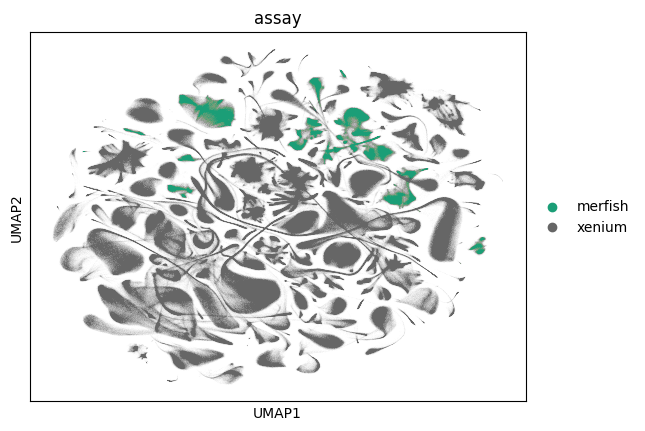

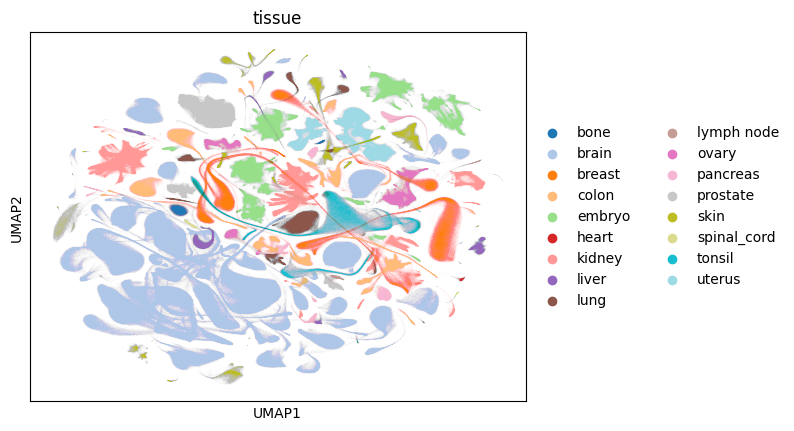

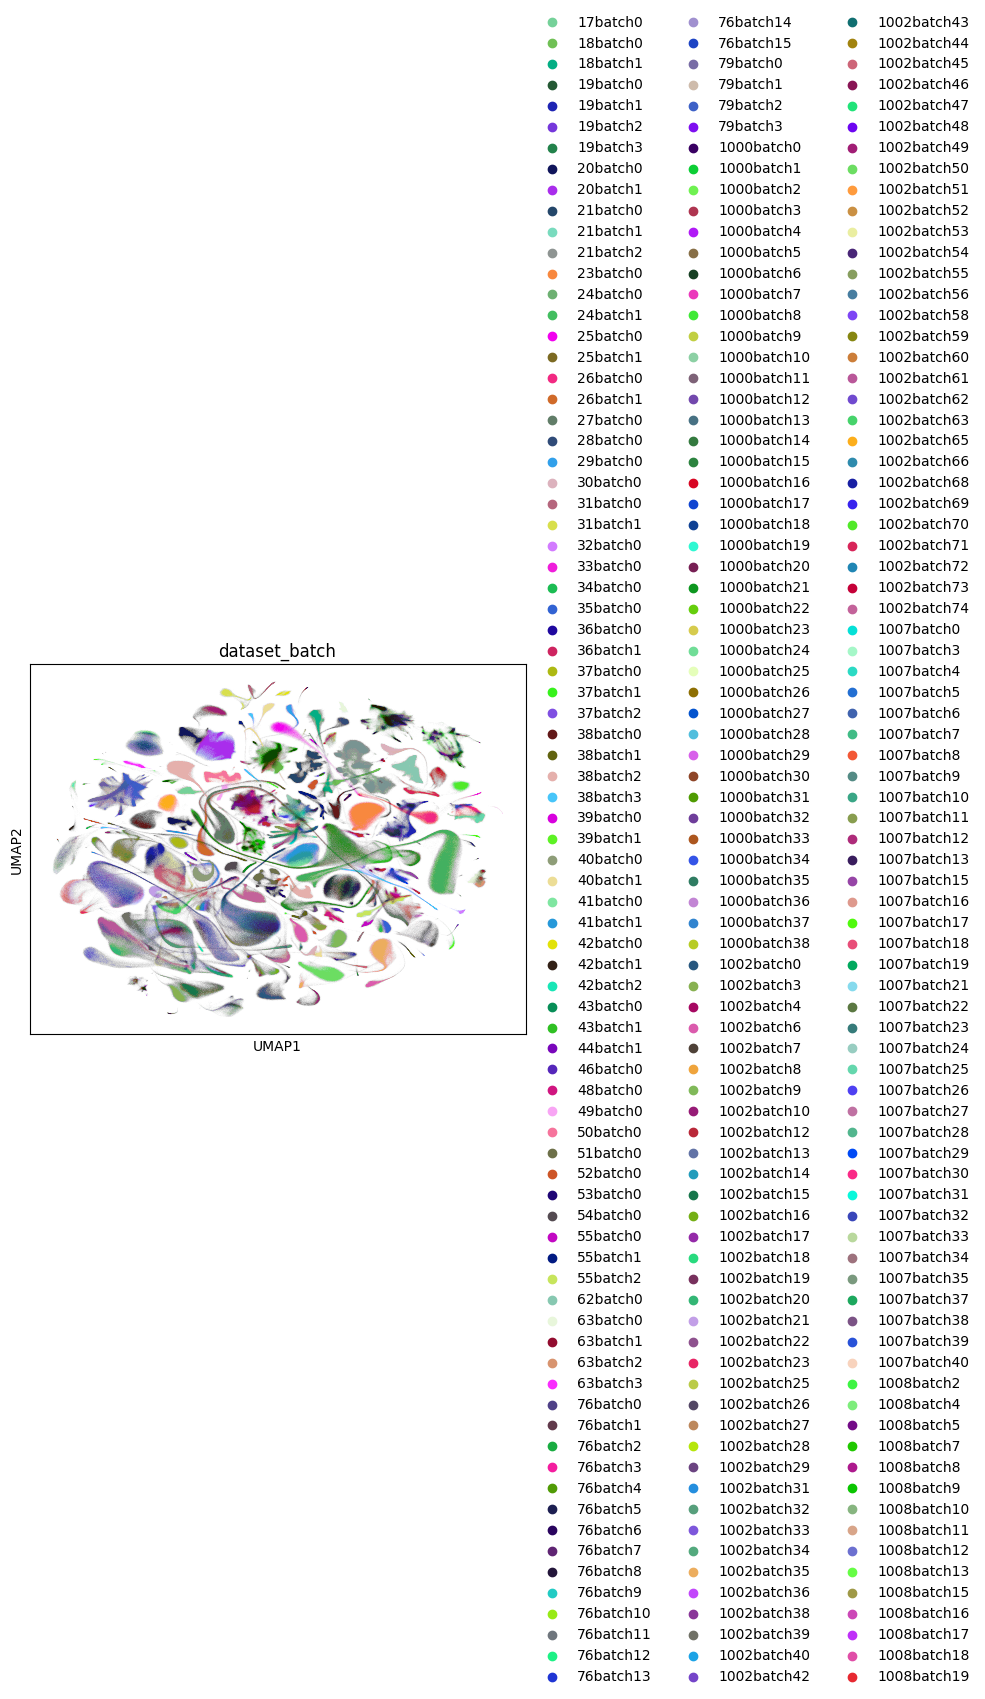

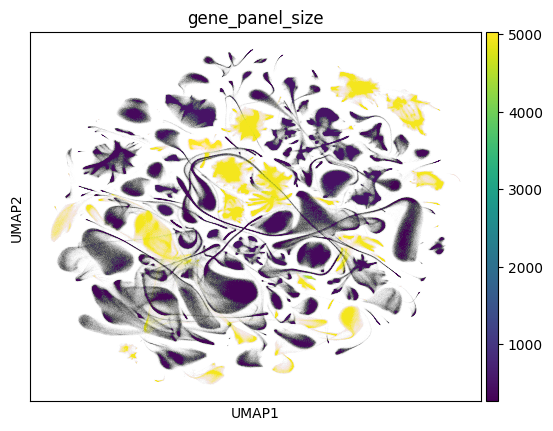

In [78]:
labels = ['assay', 'tissue', 'dataset_batch', 'gene_panel_size']
# Plot (aggregated) neighborhood gene embeddings, colored by labels
for label in labels:
    if label == 'assay':
        palette = 'Dark2'
    elif label == 'tissue':
        palette = 'tab20'
    elif label == 'dataset_batch':
        palette = dataset_batch_palette
    sc.pl.umap(adata_full,
               color=label,
               palette=palette,
               show=False)
    plt.savefig(f'{artifacts_folder_path}/hst_corpus_70m/{load_timestamp}/hst_corpus_70m_{sample_frac}_subsample_{label}_umap.svg',
                dpi=300,
                bbox_inches='tight')

In [51]:
artifacts_folder_path

'/lustre/scratch126/cellgen/team361/sb75/nichejepa-reproducibility/artifacts'

In [27]:
!free -h

               total        used        free      shared  buff/cache   available
Mem:           3.9Ti       875Gi       2.7Ti        11Mi       407Gi       3.1Ti
Swap:           67Gi        34Mi        67Gi


In [ ]:
len(adata_temp)

In [ ]:
len(set(sampled_df.index.tolist()))

In [ ]:
sampled_df['batch'].unique()

In [ ]:
len(sampled_df)

In [ ]:
sampled_df.head(5)

In [ ]:
adata_full.obs.index.tolist()

In [ ]:
import time
from datetime import timedelta

start_time = time.time()
print("Start time:", start_time)

# Compute neighbors and UMAP 
sc.pp.neighbors(adata_full,
                n_neighbors=15,
                use_rep=emb_key,
                key_added='neighborhood')

intermediate_time = time.time()
print("Intermediate time:", intermediate_time)

elapsed_time = intermediate_time - start_time
print("Elapsed time:", str(timedelta(seconds=elapsed_time)))

sc.tl.umap(adata,
           neighbors_key='neighborhood')

end_time = time.time()
print("End time:", end_time)

elapsed_time = end_time - start_time
print("Elapsed time:", str(timedelta(seconds=elapsed_time)))

In [ ]:
adata.write('./temp.h5ad')

In [ ]:
!free -h

In [ ]:
adata.obs.columns

In [ ]:
adata.uns

In [ ]:
from pathlib import Path
folder_path = Path(f'/lustre/scratch126/cellgen/team361/DATASETS/silver/xhb1002-AT9-6b_1p')
adata_path_list = [p for p in folder_path.rglob("*")]

In [ ]:
for adata_path in adata_path_list:
    adata = sc.read_h5ad(adata_path)
    print(f'{adata_path}: {adata.uns["batch"]}')

In [ ]:
import pickle
import pprint

In [ ]:
token_dict_path = '/lustre/scratch126/cellgen/team361/DATASETS/tokenizer/token_dictionary_homo_sapiens.pkl'

with open(token_dict_path, 'rb') as f:
    token_dict = pickle.load(f)

In [ ]:
pp = pprint.PrettyPrinter(indent=4, width=40, depth=2)
pp.pprint(token_dict)

In [ ]:
token_dict['spv_gene_panel4949']

In [ ]:
token_dict['spv_embryo'] = token_dict.pop('dummy_0')

token_dict['spv_gene_panel4949'] = token_dict.pop('dummy_1')

for i in range(2,22):
    token_dict[f'spv_1008_batch{i-2}'] = token_dict.pop(f'dummy_{i}')

In [ ]:
pp = pprint.PrettyPrinter(indent=4, width=40, depth=2)
pp.pprint(token_dict)

In [ ]:
import scanpy as sc

In [ ]:
dataset_folder_path = '/lustre/scratch126/cellgen/team361/DATASETS'

In [ ]:
adata = sc.read_h5ad(f'{dataset_folder_path}/silver/xhe1008-1-20b_1p/section173_SOB26.h5ad')

In [ ]:
adata

In [ ]:
adata.var

In [ ]:
# coronal 10 slide_id
# sagittal 6
# 

In [ ]:
adata

In [ ]:
adata.obs.head(1)

In [ ]:
adata.obs['slide_id'].unique()

In [ ]:
adata_batch = adata[adata.obs['slide_id'] == 'B2']

In [ ]:
sc.pl.spatial(adata_batch,
              color='subregion',
              spot_size=30)

In [ ]:
with open(token_dict_path, 'wb') as f:
    pickle.dump(token_dict, f)

In [ ]:
import json

In [ ]:
json_file = '/lustre/scratch126/cellgen/team361/data/sanger_whole_embryo/xenium/section020_SOB26/output-XETG00155__0004457__SOB26-WEM-FFPE-1-S20__20240912__123924/gene_panel.json'

In [ ]:
with open(json_file, 'r') as file:
    gene_panel = json.load(file)

In [ ]:
gene_panel.keys()

In [ ]:
len(gene_panel['payload']['targets'])

In [ ]:
gene_panel['metadata']

In [ ]:
# Pickle the list
with open("human_cohort2_60m_32_gene_corrected_read_depth_nonzero_mean_None_gene_corrected_read_depth_None_shifted_log_knn_10_train.pkl", "rb") as f:
    train = pickle.load(f)

with open("human_cohort2_60m_32_gene_corrected_read_depth_nonzero_mean_None_gene_corrected_read_depth_None_shifted_log_knn_10_test.pkl", "rb") as f:
    test = pickle.load(f)

with open("human_cohort2_60m_32_None_None_None_gene_corrected_read_depth_None_shifted_log_knn_10_train.pkl", "rb") as f:
    new_train = pickle.load(f)

with open("human_cohort2_60m_32_None_None_None_gene_corrected_read_depth_None_shifted_log_knn_10_test.pkl", "rb") as f:
    new_test = pickle.load(f)

print(len(train))
print(len(test))
print(len(new_train))
print(len(new_test))

train_matches = set(train).intersection(new_train)
print(len(train_matches))
test_matches = set(test).intersection(new_test)
print(len(test_matches))

train_differences = []
for i in range(len(train)):
    if train[i] != new_train[i]:
        train_differences.append((i, train[i], new_train[i]))
print(train_differences)
print(len(differences))

test_differences = []
for i in range(len(test)):
    if test[i] != new_test[i]:
        test_differences.append((i, test[i], new_test[i]))
print(test_differences[-10:])

In [ ]:
import scanpy as sc
adata = sc.read_h5ad(/adata_batch0.h5ad')

In [ ]:
import os

In [ ]:
for subdir, _, files in os.walk('/lustre/scratch126/cellgen/team361/DATASETS/silver/xhb1002-AT9-6b_1p'):
    for file_idx, file in enumerate(files):
        if file.endswith('.h5ad'):
            file_path = os.path.join(subdir, file)
            adata = sc.read_h5ad(file_path)
            print(file_path)
            print(adata.obs['cell_id'].values[0])
            #print(adata.obs['sample'].unique())
            print(adata.uns['batch'])
            print("================")

In [ ]:
adata.X.toarray()

In [ ]:
import numpy as np
adata.X = adata.X.astype(np.float64)

In [ ]:
sc.pp.pca(adata, svd_solver="arpack", use_highly_variable=False)
sc.pp.neighbors(adata)
sc.tl.umap(adata)

In [ ]:
sc.pl.umap(adata, color='niche_name')

In [ ]:
scales_counts = sc.pp.normalize_total(adata, target_sum=None, inplace=False)
adata.X = sc.pp.log1p(scales_counts["X"], copy=True)
sc.pp.pca(adata, svd_solver="arpack", use_highly_variable=False)
sc.pp.neighbors(adata)
sc.tl.umap(adata)

In [ ]:
sc.pl.umap(adata, color='niche_name')

In [ ]:
sc.pl.spatial(adata,
              color='niche_name',
              spot_size=30)

In [ ]:
adata.obs['niche_name'].value_counts()

In [ ]:
sc.pp.calculate_qc_metrics(
    adata,
    inplace=True
)

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.histplot(data=adata.obs, x='n_genes_by_counts', bins=100)
plt.xlabel('Number of expressed genes per cell')
plt.ylabel('Number of cells')
plt.show()

In [ ]:
adata.obsm['spatial_connectivities']

In [ ]:
# Load hold out skin samples and concatenate in one adata object
adata_list = []

for subdir, _, files in os.walk('/lustre/scratch126/cellgen/team361/DATASETS/silver/xhs1000-39b_1p'):
    for file_idx, file in enumerate(files):
        if file.endswith('.h5ad'):
            file_path = os.path.join(subdir, file)
            adata = sc.read_h5ad(file_path)
            print(adata.X)
            adata.X = adata.X.astype(int64)
            print(adata.X)

adata = ad.concat(adata_list, join='outer', index_unique=None)

In [ ]:
adata2 = sc.read_h5ad('/lustre/scratch126/cellgen/team361/DATASETS/silver/mmb0-1b_smb1-1b_1p/harmonised_starmap_plus_mouse_cns_batch15_shared_genes.h5ad')

In [ ]:
import pickle

# Path to your pickle file
pickle_file_path = '/lustre/scratch126/cellgen/team361/DATASETS/tokenizer/cell-graph-tokenizer/human_cohort1_10m/token_dictionary.pkl'

# Load the pickle file
with open(pickle_file_path, 'rb') as file:
    token_dict = pickle.load(file)

# Now `token_dict` is a Python dictionary
print(token_dict)

In [ ]:
spv_count = sum(1 for key in token_dict if "spv" in key)
spv_count

In [ ]:
len(token_dict)

In [ ]:
import os
import pickle

import scanpy as sc
import squidpy as sq

In [ ]:
folder_path = '/lustre/scratch126/cellgen/team361/DATASETS/silver/xhs1000-39b_1p'
token_dict_path = '/lustre/scratch126/cellgen/team361/DATASETS/tokenizer/cell-neighborhood-tokenizer/xhs1000-39b_1p/token_dictionary.pkl'

In [ ]:
with open(token_dict_path, 'rb') as f:
    token_dict = pickle.load(f)

In [ ]:
len(token_dict)

In [ ]:
count_spv_keys = sum(1 for key in token_dict if key.startswith("spv"))
count_spv_keys

In [ ]:
token_dict[list(token_dict.keys())[-1:][0]]

In [ ]:
token_dict['ENSG00000292373']

In [ ]:
max_nonzero_counts = 0  # Initialize a variable to store the maximum count
neighbor_max_nonzero_counts = 0

# Iterate through all .h5ad files in the folder
for filename in os.listdir(folder_path):
    if filename.endswith('.h5ad'):
        file_path = os.path.join(folder_path, filename)
        
        # Load the .h5ad file
        adata = sc.read_h5ad(file_path)

        sq.gr.spatial_neighbors(adata,
                                coord_type='generic',
                                spatial_key='spatial',
                                delaunay=True,
                                set_diag=True)

        adata.layers['X_neighborhood'] = (
                adata.obsp['spatial_connectivities'].T @ adata.X)
        
        # Calculate nonzero counts per cell
        nonzero_counts = (adata.X > 0).sum(axis=1)
        neighbor_nonzero_counts = (adata.layers['X_neighborhood'] > 0).sum(axis=1)
        
        # Get the maximum nonzero count in the current file
        file_max_nonzero = nonzero_counts.max()
        file_max_neighbor_nonzero = neighbor_nonzero_counts.max()
        
        # Update the overall maximum if the current file has a higher value
        if file_max_nonzero > max_nonzero_counts:
            max_nonzero_counts = file_max_nonzero

        if file_max_neighbor_nonzero > neighbor_max_nonzero_counts:
            neighbor_max_nonzero_counts = file_max_neighbor_nonzero

In [ ]:
adata.obs

In [ ]:
max_nonzero_counts

In [ ]:
neighbor_max_nonzero_counts

In [ ]:
adata_test = sc.read_h5ad('/lustre/scratch126/cellgen/team361/DATASETS/bronze/xhs1000-1b_1p/adata_5k_xenium_skin.h5ad')

In [ ]:
adata_test.obs['info_id']

In [ ]:
batch_mapping_dict = {value: idx for idx, value in enumerate(adata_test.obs['info_id'].unique().tolist())}

In [ ]:
batch_mapping_dict # 19, 11, 32

In [ ]:
2+3

In [ ]:
import os
import shutil

main_directory = '/lustre/scratch126/cellgen/team361/DATASETS/bronze/xhe1010-20b_1p'
keyword = 'output'  # Adjust this to match your criteria

for subdir in os.listdir(main_directory):
    subdir_path = os.path.join(main_directory, subdir)
    if os.path.isdir(subdir_path):
        # Find nested directories in the subdirectory.
        nested_dirs = [
            d for d in os.listdir(subdir_path)
            if os.path.isdir(os.path.join(subdir_path, d))
        ]
        
        # Option A: If there is exactly one nested directory, zip that one.
        if len(nested_dirs) == 1:
            target = nested_dirs[0]
        # Option B: If there are multiple, pick the one whose name contains the keyword.
        else:
            target = next((d for d in nested_dirs if keyword in d), None)
        
        if target is not None:
            target_dir_path = os.path.join(subdir_path, target)
            archive_base = os.path.join(subdir_path, target)
            shutil.make_archive(base_name=archive_base, format='zip', root_dir=target_dir_path)
            print(f"Created zip archive: {archive_base}.zip")
        else:
            print(f"No matching nested directory found in {subdir_path}")

In [ ]:
'/lustre/scratch126/cellgen/team361/DATASETS/bronze/xhe1009-20b_1p/section056_SOB26/output-XETG00155__0003607__SOB25-WEM-FFPE-1-S56__20240912__123924.zip'

In [ ]:
chmod -R u+rw /lustre/scratch126/cellgen/team361/DATASETS/bronze/xhe1009-20b_1p
